# Big Data 2026/2027 ősz | Data Science Beadandó | Dékán Máté (GQHTIH)

## Importok

In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## Adatbeolvasás

In [42]:
input_df = pd.read_csv("data/input.csv")              # tanító adat, van class
validation_df = pd.read_csv("data/validation.csv")    # erre kell jósolni, nincs class
print(input_df.head(5))
print("Input: ", input_df.shape, "| Validation: ", validation_df.shape)

   cap-diameter  stem-height  stem-width        date cap-shape cap-color  \
0          5.35         5.65        4.60  2020.04.01         x         g   
1          6.62         5.61        7.08  2020.04.11         b         n   
2          4.96         4.99        6.59  2020.06.18         x         e   
3           NaN         4.17        2.62  2020.02.05         b         w   
4          6.99         8.80       10.11  2020.09.04         x         e   

  has-ring ring-type class  
0        t         l     e  
1        t       NaN     p  
2        f         f     p  
3        f         f     e  
4        t         z     p  
Input:  (39084, 9) | Validation:  (9771, 8)


## Feltárás: Hiányzó értékek, duplikátumok, eloszlások

In [25]:
# Nullértékek
na_input = input_df.isna().sum()
na_val = validation_df.isna().sum()
print("Nullértékek")
print("input: ", na_input[na_input > 0].to_dict())
print("validation:", na_val[na_val > 0].to_dict())
# ring type: input 1590 db, validation 390 db | cap diameter: input 1 db, validation 0 db

# Duplikátumok
print("\nDuplikátumok")
print("input:", input_df.duplicated().sum(), "| validation:", validation_df.duplicated().sum())
# nincs

# Célváltozó
print("\nCélváltozó")
print(pd.DataFrame({"darab": input_df["class"].value_counts(), "arány": input_df["class"].value_counts(normalize=True).round(3)}))
# p: 21716 db, 56% | e: 17368 db, 44%

# Hiányzó ring-type és has-ring kapcsolata
print("\nhas-ring / ring-type")
print(pd.crosstab(input_df["has-ring"], input_df["ring-type"].fillna("NaN")))
# a hiányzó ring-type csak has-ring = 't' mellett fordul elő

# Numerikus oszlopok
print("\nNumerikus oszlopok")
print(input_df.describe().round(2))
print("stem-heigth 0:", ((input_df["stem-width"] == 0).sum()))
print("stem-width 0:", ((input_df["stem-height"] == 0).sum()))
print("stem-height és stem-width is 0 és mérgező:", ((input_df["stem-height"] == 0) & (input_df["stem-width"] == 0) & (input_df["class"] == 'p')).sum())
# 648 db: a két érték mindig együtt 0 és egyben p is, vagyis mind mérgező

# Dátum: mérgezők aránya hónaponként
print("\nMérgezők aránya hónaponként")
honap = pd.to_datetime(input_df["date"], format="%Y.%m.%d").dt.month
print(input_df.groupby(honap)["class"].apply(lambda s: (s == "p").mean()).round(2).to_dict())
# minden hónapban hasonló -> a dátum nem kell

Nullértékek
input:  {'cap-diameter': 1, 'ring-type': 1590}
validation: {'ring-type': 390}

Duplikátumok
input: 0 | validation: 0

Célváltozó
       darab  arány
class              
p      21716  0.556
e      17368  0.444

has-ring / ring-type
ring-type   NaN     e      f    g    l    m    p    r     z
has-ring                                                   
f             0     0  29341    0    0    0    0    0     0
t          1590  1572   1589  788  905  223  802  902  1372

Numerikus oszlopok
       cap-diameter  stem-height  stem-width
count      39083.00     39084.00    39084.00
mean           6.77         6.58       12.17
std            5.37         3.36       10.02
min            0.44         0.00        0.00
25%            3.49         4.64        5.24
50%            5.88         5.95       10.24
75%            8.54         7.74       16.61
max           62.34        33.92      102.48
stem-heigth 0: 648
stem-width 0: 648
stem-height és stem-width is 0 és mérgező: 648

Mérgező

## Adattisztítás: dátum eldobása, ring-type pótlása, X/y szétválasztás

In [26]:
def clean(df):
    df = df.copy()
    df = df.drop(columns="date") # nem kell
    df = df.fillna({"ring-type": "ismeretlen"}) # null érték jelölése
    return df

# A cap-diameter 1 hiányos értékét majd az imputer pótolja

df = clean(input_df)
X_val = clean(validation_df) # valiációs adat
y = df.pop("class") # célváltozó 
X = df
print(X.shape, X_val.shape)

(39084, 7) (9771, 7)


## Átalakítás: Imputing és One-Hot kódolás

In [27]:
nominalis = ["cap-shape", "cap-color", "has-ring", "ring-type"] # külön oszlopokká
szam = ["cap-diameter", "stem-height", "stem-width"] 
# skálázás most nem kell fák miatt

preprocessor = ColumnTransformer([
    ("szam", SimpleImputer(strategy="median"), szam), # mediánnal pótlás
    ("nom", OneHotEncoder(handle_unknown="ignore"), nominalis),   # ha ismeretlen akkor csupa 0, nem hiba
])

## Modell: Random Forest – ellenőrzés teszthalmazon és 5-szörös CV-vel

In [39]:
# Random forestre esett a választás próbálgatás után
# logreg 0.678, AdaBoost 0.670, döntési fa 0.928, k-NN 0.954, Random Forest 0.955
model = make_pipeline(preprocessor, RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))
# 300 fa kb jó, utána nem javul igazán

# felosztás: 25% megy tesztbe egyelőre, arány marad, és mindig ugyan az a seed
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
model.fit(X_tr, y_tr)
pred_te = model.predict(X_te)
print("train pontosság:", round(model.score(X_tr, y_tr), 4))   # pontosság train adaton
print("teszt pontosság: ", round(accuracy_score(y_te, pred_te), 4)) # valódi pontosság
print(classification_report(y_te, pred_te))

# Cross-validáció (stabilabb becslés egyetlen felosztásnál)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
s = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
print(f"CV accuracy = {s.mean()} +- {s.std()}")

train pontosság: 1.0
teszt pontosság:  0.9528
              precision    recall  f1-score   support

           e       0.95      0.95      0.95      4342
           p       0.96      0.96      0.96      5429

    accuracy                           0.95      9771
   macro avg       0.95      0.95      0.95      9771
weighted avg       0.95      0.95      0.95      9771

CV accuracy = 0.9555572853905139 +- 0.0020695280902929226


## Ábrák: változófontosság, confusion matrix

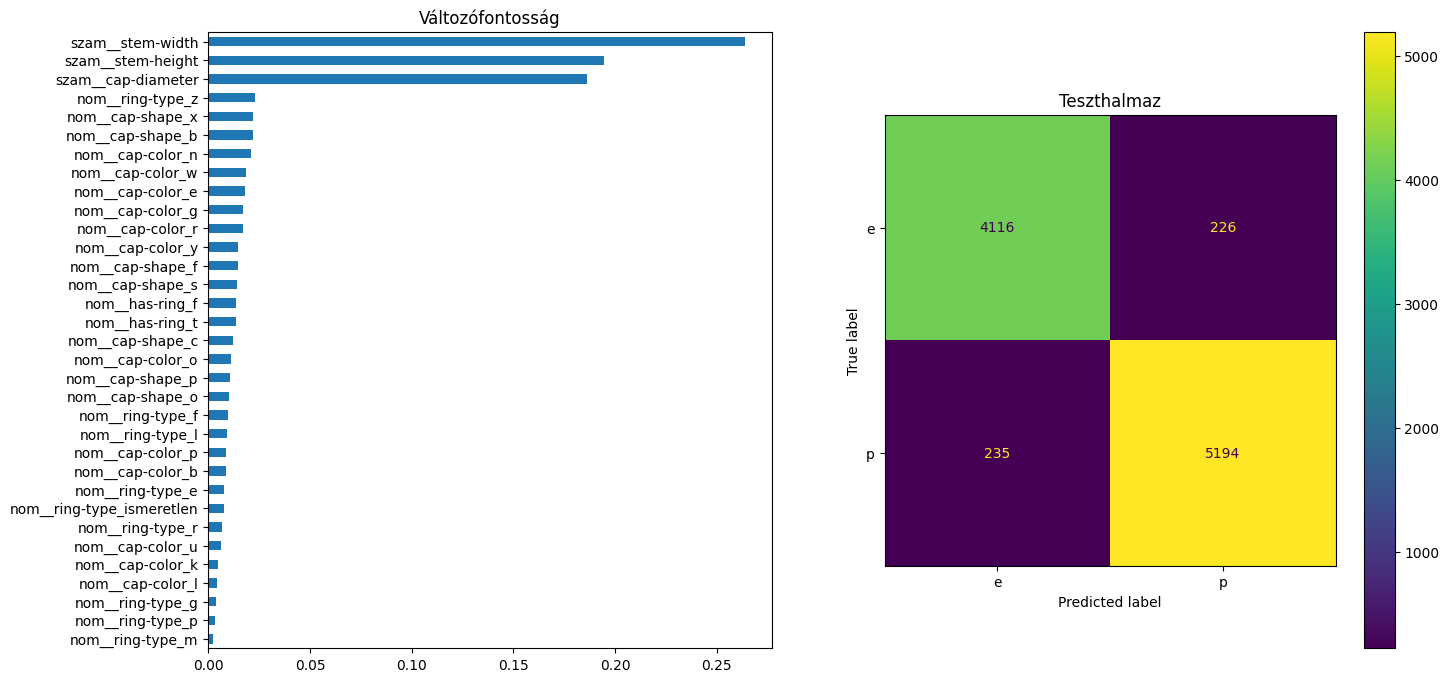

In [35]:
# One-Hot oszlopokra is külön-külön chart
imp = pd.Series(model[-1].feature_importances_, model[:-1].get_feature_names_out()).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
imp.plot.barh(ax=ax[0], title="Változófontosság")
ConfusionMatrixDisplay.from_estimator(model, X_te, y_te, ax=ax[1])
ax[1].set_title("Teszthalmaz")
plt.show()

## Előrejelzés a validációs adatra, pred.txt mentése

In [46]:
# mostmár összes adattal
model.fit(X, y)
prediction = model.predict(X_val)
print(len(prediction), pd.Series(prediction).value_counts(normalize=True).round(3).to_dict())
np.savetxt("pred.txt", prediction, fmt="%s")

9771 {'p': 0.55, 'e': 0.45}
